# Лабораторная работа №1. Линейная регрессия (Kaggle: предсказание `RiskScore`)
Выполнил: Бахшалиев Максим
Группа: М8О-311БВ-24

Ограничение из условия: **только линейная регрессия** (в том числе для отбора признаков). Поэтому вся работа сделана на линейных моделях: нелинейность в данных учитывается через признаки (логарифмы, полиномы), а сама модель остаётся линейной по параметрам. Модель, метрики, нормализация и кросс-валидация написаны вручную, `sklearn` используется только для сравнения.

**План:** 1) загрузка и очистка, 2) EDA, 3) нормализация, 4) метрики, 5) класс линейной регрессии (аналитика / GD / SGD), 6) кросс-валидация, 7) регуляризация (L1, L2, L1+L2, Lp), 8) улучшение признаков и итоговая модель.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from itertools import combinations_with_replacement

# sklearn нужен ТОЛЬКО для проверки собственных реализаций
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score, KFold, LeaveOneOut
from sklearn import metrics as skm

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

## 1. Загрузка и очистка данных

In [2]:
train_raw = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
print('train:', train_raw.shape, '| test:', test.shape)

print('\nПолностью пустых строк в train:', train_raw.isna().all(axis=1).sum())
tmp = train_raw.dropna(how='all')
print('Дубликатов среди непустых строк:', tmp.duplicated().sum())
tmp = tmp.drop_duplicates()
print('Выбросов-заглушек в RiskScore (|y| > 1e6):', (tmp['RiskScore'].abs() > 1e6).sum(),
      '->', sorted(tmp.loc[tmp['RiskScore'].abs() > 1e6, 'RiskScore'].unique()))
print('Пропусков в test:', test.isna().sum().sum())

train: (11017, 35) | test: (5000, 35)

Полностью пустых строк в train: 530
Дубликатов среди непустых строк: 487
Выбросов-заглушек в RiskScore (|y| > 1e6): 212 -> [np.float64(-9999999.0), np.float64(10000000.0)]
Пропусков в test: 0


In [3]:
train = train_raw.dropna(how='all')                 # 1) пустые строки
train = train.drop_duplicates()                     # 2) дубликаты
train = train[train['RiskScore'].abs() < 1e6]       # 3) заглушки ±9999999 / 10000000 в целевой переменной
print('Строк с пропусками в признаках:', train.isna().any(axis=1).sum(),
      '(пропуски идут блоком в одних и тех же колонках)')
train = train.dropna().reset_index(drop=True)       # 4) строки с пропусками (в test пропусков нет)
print('Итоговый размер train:', train.shape)

Строк с пропусками в признаках: 456 (пропуски идут блоком в одних и тех же колонках)
Итоговый размер train: (9332, 35)


Что было в данных: 530 полностью пустых строк, 487 дубликатов, 212 строк с «заглушками» в `RiskScore` (±10⁷, это явно не настоящие значения) и ~450 строк с пропущенным блоком признаков. Так как в `test.csv` пропусков нет, такие строки из обучения просто удалены. После очистки остаётся 9332 строки.

## 2. Разведочный анализ данных (EDA)

count   9332.000
mean      48.313
std       17.243
min       14.841
25%       32.693
50%       44.127
75%       65.059
max       97.597
Name: RiskScore, dtype: float64


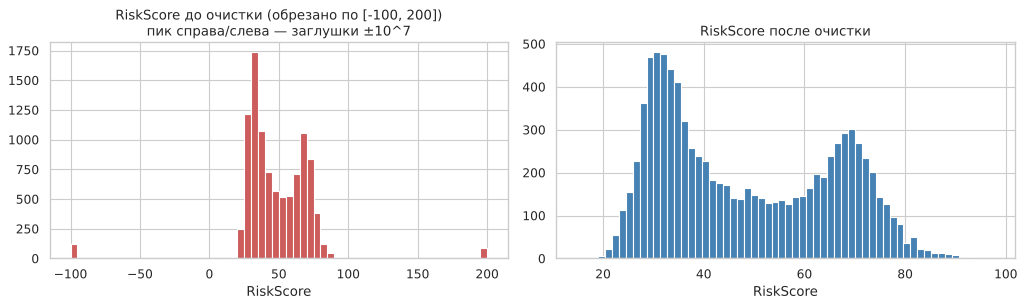

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
raw = train_raw.dropna(how='all').drop_duplicates()['RiskScore']
axes[0].hist(raw.clip(-100, 200), bins=60, color='indianred')
axes[0].set_title('RiskScore до очистки (обрезано по [-100, 200])\nпик справа/слева — заглушки ±10^7')
axes[1].hist(train['RiskScore'], bins=60, color='steelblue')
axes[1].set_title('RiskScore после очистки')
for a in axes: a.set_xlabel('RiskScore')
plt.tight_layout(); plt.show()
print(train['RiskScore'].describe())

Корреляция с RiskScore:
CreditScore              -0.785
MonthlyIncome            -0.770
BaseInterestRate          0.760
AnnualIncome             -0.758
InterestRate              0.744
TotalDebtToIncomeRatio    0.554
BankruptcyHistory         0.180
TotalAssets              -0.147
MonthlyLoanPayment        0.147
NetWorth                 -0.146
Name: RiskScore, dtype: float64


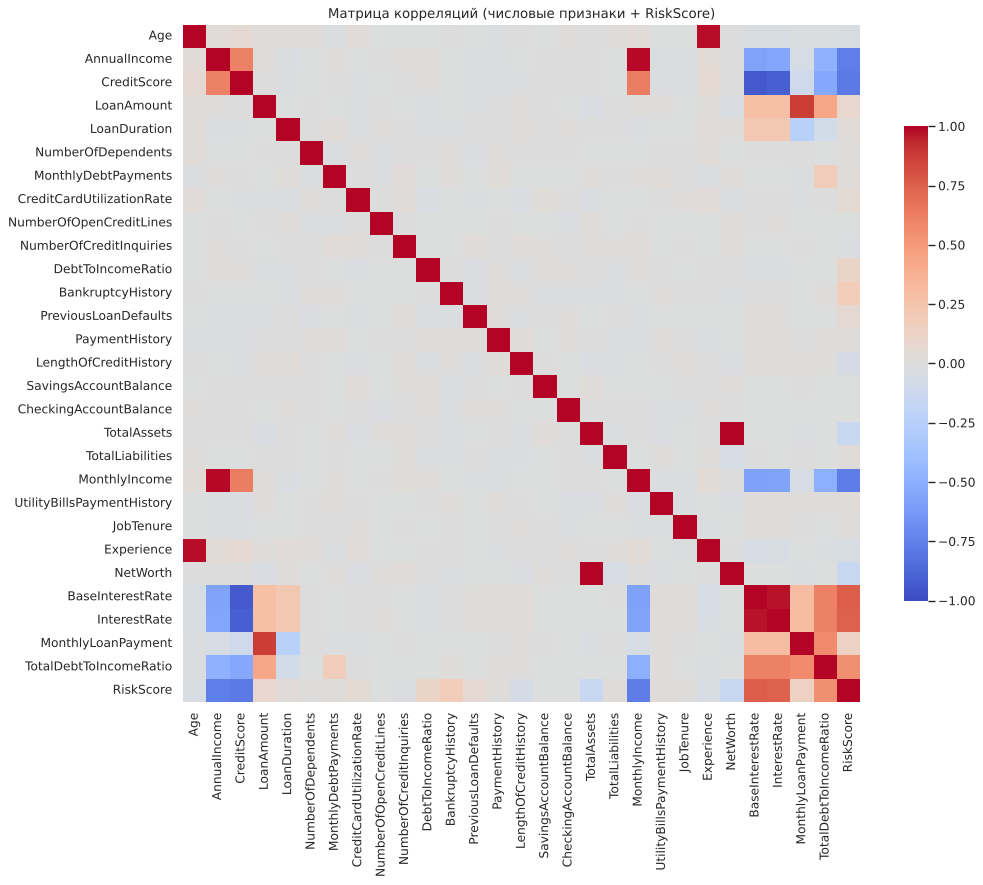

In [5]:
num = train.select_dtypes('number')
corr = num.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True, cbar_kws={'shrink': 0.7})
plt.title('Матрица корреляций (числовые признаки + RiskScore)')
plt.show()
print('Корреляция с RiskScore:')
print(corr['RiskScore'].drop('RiskScore').sort_values(key=abs, ascending=False).head(10))

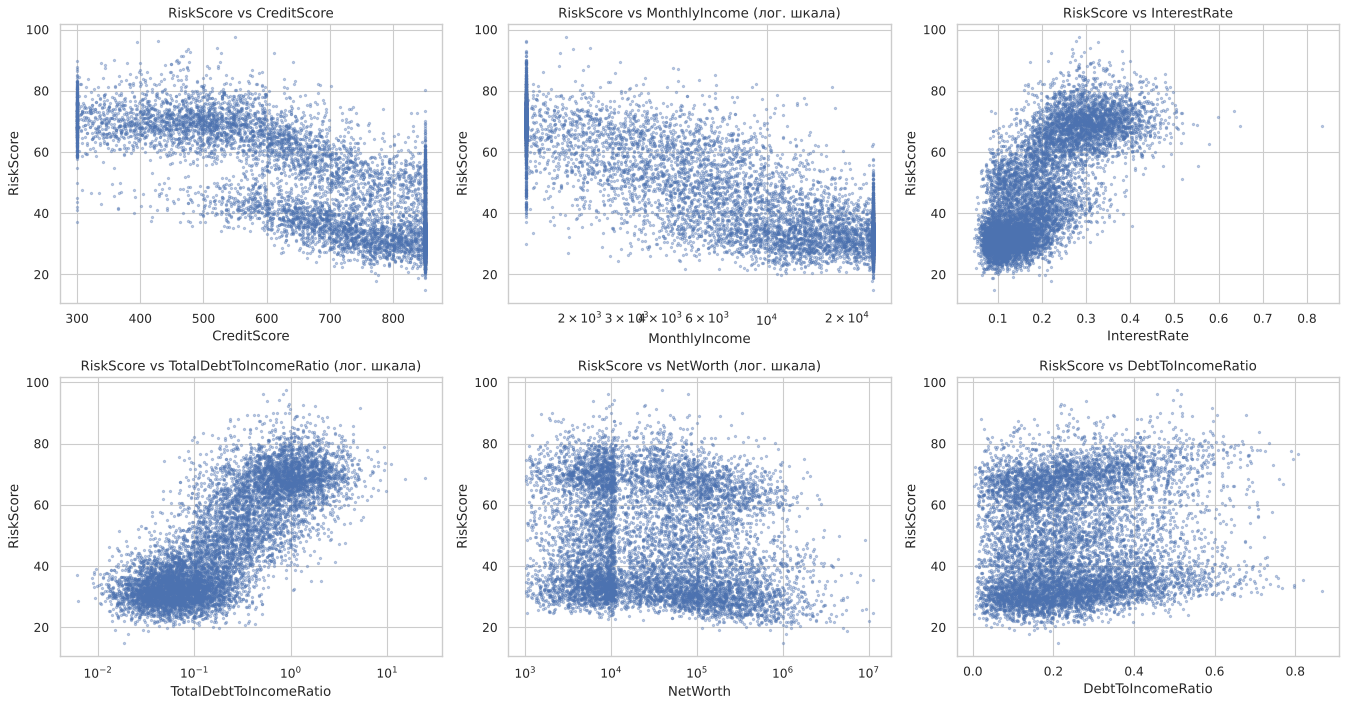

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plots = [('CreditScore', False), ('MonthlyIncome', True), ('InterestRate', False),
         ('TotalDebtToIncomeRatio', True), ('NetWorth', True), ('DebtToIncomeRatio', False)]
for ax, (c, logx) in zip(axes.ravel(), plots):
    ax.scatter(train[c], train['RiskScore'], s=4, alpha=0.35)
    if logx: ax.set_xscale('log')
    ax.set_title(f'RiskScore vs {c}' + (' (лог. шкала)' if logx else '')); ax.set_xlabel(c); ax.set_ylabel('RiskScore')
plt.tight_layout(); plt.show()

CreditScore: значений ровно 300 и 850: 452 2892
MonthlyIncome: значений ровно 1250 и 25000: 2100 2017


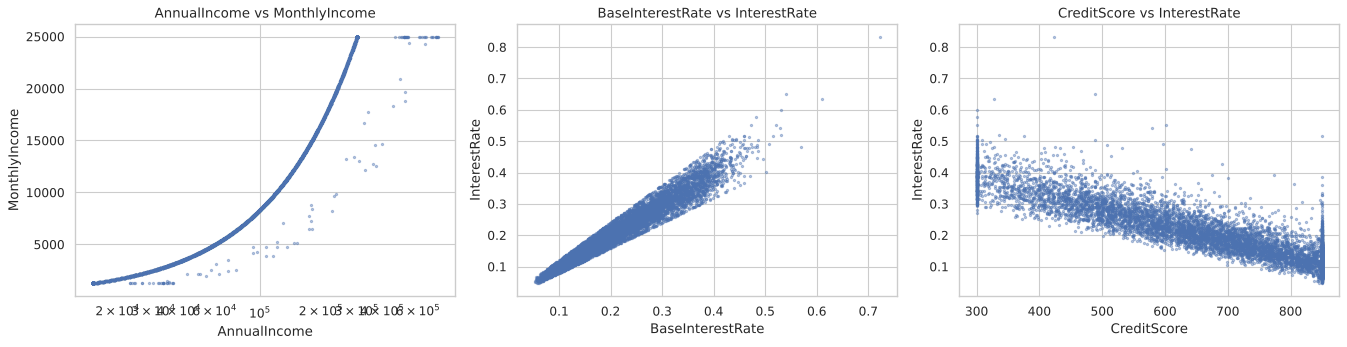

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(train['AnnualIncome'], train['MonthlyIncome'], s=4, alpha=0.4); axes[0].set_xscale('log')
axes[0].set_title('AnnualIncome vs MonthlyIncome'); axes[0].set_xlabel('AnnualIncome'); axes[0].set_ylabel('MonthlyIncome')
axes[1].scatter(train['BaseInterestRate'], train['InterestRate'], s=4, alpha=0.4)
axes[1].set_title('BaseInterestRate vs InterestRate'); axes[1].set_xlabel('BaseInterestRate'); axes[1].set_ylabel('InterestRate')
axes[2].scatter(train['CreditScore'], train['InterestRate'], s=4, alpha=0.4)
axes[2].set_title('CreditScore vs InterestRate'); axes[2].set_xlabel('CreditScore'); axes[2].set_ylabel('InterestRate')
plt.tight_layout(); plt.show()

print('CreditScore: значений ровно 300 и 850:', (train.CreditScore == 300).sum(), (train.CreditScore == 850).sum())
print('MonthlyIncome: значений ровно 1250 и 25000:', (train.MonthlyIncome == 1250).sum(), (train.MonthlyIncome == 25000).sum())

### Выводы по EDA
- **Целевая переменная** после очистки лежит в диапазоне 14.8–97.6 (среднее 48.3, std 17.2) и **бимодальна**: два пика около 32 и 68. То есть есть два «режима» риска, между которыми объекты переключаются нелинейно. Простая линейная модель по исходным признакам такую форму описывать не будет, это объясняет результаты ниже.
- **Сильнее всего с целью связаны** `CreditScore` (r = −0.79), `MonthlyIncome` (−0.77), `BaseInterestRate` (+0.76), `AnnualIncome` (−0.76), `InterestRate` (+0.74) и `TotalDebtToIncomeRatio` (+0.55). Остальные признаки (возраст, стаж, остатки на счетах, число кредитных линий, запросов и т. д.) почти не коррелируют с целью (|r| < 0.2).
- **Мультиколлинеарность:** `Age`–`Experience` (≈1), `AnnualIncome`–`MonthlyIncome` (по сути одно и то же, `MonthlyIncome` = доход/12 с обрезкой), `BaseInterestRate`–`InterestRate`, `TotalAssets`–`NetWorth`, `LoanAmount`–`MonthlyLoanPayment`. Для аналитического решения это допустимо, но коэффициенты таких признаков неустойчивы, поэтому регуляризация полезна.
- **Нелинейность и обрезка:** зависимости от `CreditScore`, дохода и долговой нагрузки S-образные/двухполосные (диаграммы рассеяния). У `CreditScore` много значений ровно 300 и 850 (452 и 2892), у `MonthlyIncome` — 1250 и 25000 (2100 и 2017): часть информации «срезана», поэтому добавляем индикаторы обрезки. Тяжёлые хвосты у доходов/активов/сумм — для них берём логарифмы.
- `InterestRate` падает с ростом `CreditScore`: признаки взаимосвязаны, часть информации о риске дублируется.

## 3. Нормализация данных: z-score и min-max

In [8]:
class MyStandardScaler:
    def fit(self, X):
        X = np.asarray(X, float); self.mean_ = X.mean(axis=0); self.std_ = X.std(axis=0); self.std_[self.std_ == 0] = 1.0; return self
    def transform(self, X): return (np.asarray(X, float) - self.mean_) / self.std_
    def fit_transform(self, X): return self.fit(X).transform(X)

class MyMinMaxScaler:
    def fit(self, X):
        X = np.asarray(X, float); self.min_ = X.min(axis=0); self.rng_ = X.max(axis=0) - self.min_; self.rng_[self.rng_ == 0] = 1.0; return self
    def transform(self, X): return (np.asarray(X, float) - self.min_) / self.rng_
    def fit_transform(self, X): return self.fit(X).transform(X)

In [9]:
# Проверка: сравниваем с sklearn на нескольких числовых столбцах
cols = ['Age', 'AnnualIncome', 'CreditScore', 'InterestRate', 'NetWorth']
A = train[cols].values
print('z-score совпадает с StandardScaler:', np.allclose(MyStandardScaler().fit_transform(A), StandardScaler().fit_transform(A)))
print('min-max совпадает с MinMaxScaler: ', np.allclose(MyMinMaxScaler().fit_transform(A), MinMaxScaler().fit_transform(A)))
print('\nПосле z-score: mean ≈', MyStandardScaler().fit_transform(A).mean(axis=0).round(6), ' std ≈', MyStandardScaler().fit_transform(A).std(axis=0).round(3))
mm = MyMinMaxScaler().fit_transform(A); print('После min-max: min =', mm.min(axis=0), ' max =', mm.max(axis=0))

z-score совпадает с StandardScaler: True
min-max совпадает с MinMaxScaler:  True

После z-score: mean ≈ [ 0.  0. -0. -0.  0.]  std ≈ [1. 1. 1. 1. 1.]
После min-max: min = [0. 0. 0. 0. 0.]  max = [1. 1. 1. 1. 1.]


## 4. Метрики: MSE, MAE, R², MAPE

In [10]:
def mse(y, p): y, p = np.asarray(y, float), np.asarray(p, float); return np.mean((y - p) ** 2)
def mae(y, p): y, p = np.asarray(y, float), np.asarray(p, float); return np.mean(np.abs(y - p))
def r2(y, p): y, p = np.asarray(y, float), np.asarray(p, float); return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
def mape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return np.mean(np.abs(y - p) / np.maximum(np.abs(y), np.finfo(np.float64).eps))  # как в sklearn: доля, не %

In [11]:
rng = np.random.default_rng(1)
y_true = rng.normal(50, 15, 1000)
y_pred = y_true + rng.normal(0, 5, 1000)
rows = [('MSE',  mse(y_true, y_pred),  skm.mean_squared_error(y_true, y_pred)),
        ('MAE',  mae(y_true, y_pred),  skm.mean_absolute_error(y_true, y_pred)),
        ('R2',   r2(y_true, y_pred),   skm.r2_score(y_true, y_pred)),
        ('MAPE', mape(y_true, y_pred), skm.mean_absolute_percentage_error(y_true, y_pred))]
res = pd.DataFrame(rows, columns=['metric', 'моя реализация', 'sklearn'])
res['совпадает'] = np.isclose(res['моя реализация'], res['sklearn'])
res

  metric  моя реализация  sklearn  совпадает
0    MSE          26.279   26.279       True
1    MAE           4.108    4.108       True
2     R2           0.880    0.880       True
3   MAPE           0.096    0.096       True

## 5. Линейная регрессия: аналитическое решение, GD и SGD
Класс `MyLinearRegression` с методами `fit` и `predict`. Способ обучения выбирается параметром `method`:
- `analytic` — аналитическая формула (нормальные уравнения) $w = (X^TX)^{-1}X^Ty$;
- `gd` — градиентный спуск по всей выборке;
- `sgd` — стохастический градиентный спуск (случайный мини-батч, по умолчанию 1 объект) с затухающим шагом.

Сразу заложена регуляризация (раздел 7): параметры `reg` (`None`, `'l1'`, `'l2'`, `'elastic'`, `'lp'`), `alpha`, `l1_ratio`, `p`. Функция потерь записана так же, как в `sklearn`, поэтому результаты можно сравнивать напрямую.

In [12]:
class MyLinearRegression:
    """Лосс: 1/(2n)*||y - Xw||^2 + alpha * penalty(w)   (как в sklearn Lasso/ElasticNet; bias не штрафуется)
       penalty: None | 'l1' ||w||_1 | 'l2' 0.5||w||_2^2 | 'elastic' l1_ratio*||w||_1 + 0.5*(1-l1_ratio)*||w||_2^2 | 'lp' (1/p)*sum|w|^p"""
    def __init__(self, method='analytic', reg=None, alpha=0.0, l1_ratio=0.5, p=2.0,
                 lr=0.05, n_iter=2000, batch_size=1, random_state=0):
        self.method, self.reg, self.alpha, self.l1_ratio, self.p = method, reg, alpha, l1_ratio, p
        self.lr, self.n_iter, self.batch_size, self.random_state = lr, n_iter, batch_size, random_state

    def _penalty_grad(self, w):                       # градиент штрафа по w (без bias)
        if self.reg is None or self.alpha == 0: return np.zeros_like(w)
        if self.reg == 'l1': g = np.sign(w)
        elif self.reg == 'l2': g = w
        elif self.reg == 'elastic': g = self.l1_ratio * np.sign(w) + (1 - self.l1_ratio) * w
        elif self.reg == 'lp': g = np.abs(w) ** (self.p - 1) * np.sign(w)
        else: raise ValueError(self.reg)
        return self.alpha * g

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float); n, m = X.shape
        Xb = np.c_[np.ones(n), X]                     # добавляем столбец единиц под bias
        if self.method == 'analytic':
            if self.reg not in (None, 'l2'): raise ValueError('analytic: только reg=None или reg="l2"')
            reg = np.eye(m + 1) * (self.alpha if self.reg == 'l2' else 0.0); reg[0, 0] = 0   # bias не штрафуем
            self.w_ = np.linalg.solve(Xb.T @ Xb / n + reg + 1e-10 * np.eye(m + 1), Xb.T @ y / n)
        elif self.method in ('gd', 'sgd'):
            rng = np.random.default_rng(self.random_state); w = np.zeros(m + 1)
            bs = n if self.method == 'gd' else self.batch_size
            for it in range(self.n_iter):
                if self.method == 'gd': idx = slice(None)
                else: idx = rng.integers(0, n, bs)    # случайный мини-батч (при bs=1 — классический SGD)
                Xi, yi = Xb[idx], y[idx]
                grad = Xi.T @ (Xi @ w - yi) / len(yi)
                grad[1:] += self._penalty_grad(w[1:])
                lr = self.lr if self.method == 'gd' else self.lr / (1 + 1e-3 * it) ** 0.75   # затухающий шаг для SGD
                w -= lr * grad
            self.w_ = w
        else: raise ValueError(self.method)
        self.intercept_, self.coef_ = self.w_[0], self.w_[1:]
        return self

    def predict(self, X): return self.intercept_ + np.asarray(X, float) @ self.coef_

### Признаки и сравнение с sklearn
Базовый набор признаков: все числовые + логарифмы «тяжёлых» величин (доходы, активы, суммы; распределения скошены) + индикаторы обрезанных значений (`CreditScore` = 300/850, `MonthlyIncome` = 1250/25000) + one-hot для категорий. Даты не используются (в EDA они не показали связи с целью).

In [13]:
def train_val_split(X, y, val_size=0.2, seed=0):
    idx = np.random.default_rng(seed).permutation(len(y)); nv = int(len(y) * val_size)
    return X[idx[nv:]], X[idx[:nv]], y[idx[nv:]], y[idx[:nv]]

cat_cols = ['MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']
log_cols = ['AnnualIncome', 'LoanAmount', 'TotalAssets', 'TotalLiabilities', 'NetWorth', 'SavingsAccountBalance',
            'CheckingAccountBalance', 'MonthlyDebtPayments', 'MonthlyLoanPayment', 'MonthlyIncome', 'TotalDebtToIncomeRatio']

def make_features(df):
    d = df.drop(columns=[c for c in ['ID', 'RiskScore', 'ApplicationDate'] if c in df]).copy()
    for c in log_cols:
        d['log_' + c] = np.log(d[c])
    d['cs_300'] = (d.CreditScore == 300) * 1.;      d['cs_850'] = (d.CreditScore == 850) * 1.
    d['mi_1250'] = (d.MonthlyIncome == 1250) * 1.;  d['mi_25000'] = (d.MonthlyIncome == 25000) * 1.
    return pd.get_dummies(d, columns=cat_cols, drop_first=True, dtype=float)

F = make_features(train)
y = train['RiskScore'].values
print('Матрица признаков:', F.shape)

X_tr, X_val, y_tr, y_val = train_val_split(F.values, y, val_size=0.2, seed=0)
sc = MyStandardScaler().fit(X_tr)                 # статистики считаем только по обучающей части
Xtr_z, Xval_z = sc.transform(X_tr), sc.transform(X_val)

Матрица признаков: (9332, 59)


In [14]:
models = {
    'моя: аналитика': MyLinearRegression('analytic'),
    'моя: GD':        MyLinearRegression('gd', lr=0.1, n_iter=5000),
    'моя: SGD':       MyLinearRegression('sgd', lr=0.01, n_iter=60000, batch_size=1),
    'sklearn LinearRegression': LinearRegression(),
    'sklearn SGDRegressor':     SGDRegressor(penalty=None, max_iter=50, tol=None, random_state=0),
}
rows = []
for name, m in models.items():
    m.fit(Xtr_z, y_tr); p = m.predict(Xval_z)
    rows.append((name, mse(y_val, p), mae(y_val, p), r2(y_val, p), mape(y_val, p)))
pd.DataFrame(rows, columns=['модель', 'MSE', 'MAE', 'R2', 'MAPE']).set_index('модель')

                            MSE   MAE    R2  MAPE
модель                                           
моя: аналитика           33.190 4.495 0.890 0.103
моя: GD                  33.225 4.499 0.890 0.103
моя: SGD                 33.771 4.536 0.888 0.104
sklearn LinearRegression 33.190 4.495 0.890 0.103
sklearn SGDRegressor     33.591 4.527 0.889 0.104

In [15]:
# Совпадение коэффициентов аналитического решения с sklearn и влияние вида нормализации
a = MyLinearRegression('analytic').fit(Xtr_z, y_tr)
s = LinearRegression().fit(Xtr_z, y_tr)
print('max |w_моя - w_sklearn| (аналитика):', np.abs(a.coef_ - s.coef_).max())

# min-max вместо z-score: для аналитики результат тот же (линейное преобразование признаков), для GD — нет
mm = MyMinMaxScaler().fit(X_tr); Xtr_m, Xval_m = mm.transform(X_tr), mm.transform(X_val)
print('\nMSE на валидации, аналитика:  z-score = %.3f | min-max = %.3f' % (
    mse(y_val, MyLinearRegression('analytic').fit(Xtr_z, y_tr).predict(Xval_z)),
    mse(y_val, MyLinearRegression('analytic').fit(Xtr_m, y_tr).predict(Xval_m))))
print('MSE на валидации, GD (5000 ит.): z-score = %.3f | min-max = %.3f' % (
    mse(y_val, MyLinearRegression('gd', lr=0.1, n_iter=5000).fit(Xtr_z, y_tr).predict(Xval_z)),
    mse(y_val, MyLinearRegression('gd', lr=0.2, n_iter=5000).fit(Xtr_m, y_tr).predict(Xval_m))))

max |w_моя - w_sklearn| (аналитика): 5.549119523662327e-05

MSE на валидации, аналитика:  z-score = 33.190 | min-max = 33.190
MSE на валидации, GD (5000 ит.): z-score = 33.225 | min-max = 33.423


### Выводы
- Аналитическое решение **совпадает с `sklearn.LinearRegression`** (MSE 33.190 в обоих случаях, коэффициенты отличаются на ~5·10⁻⁵ из-за коллинеарности и численных деталей).
- **GD** сходится к тому же решению (33.225), **SGD** чуть шумнее (33.77), что ожидаемо: он движется по случайным объектам с затухающим шагом. `sklearn.SGDRegressor` даёт похожий результат (33.59).
- **Нормализация:** для аналитики z-score и min-max дают одинаковый результат (признаки меняются линейно). Для градиентных методов z-score удобнее: при min-max пришлось подбирать шаг (при 0.3 GD расходится) и сходимость медленнее (33.42 против 33.23).
- Базовая линейная модель даёт **MSE ≈ 33–34, это выше порога 25**: проблема не в способе обучения, а в том, что связь нелинейна (см. EDA). Исправляем это в разделе 8.

## 6. Кросс-валидация: k-fold и leave-one-out
Обе процедуры реализованы вручную (`kfold_cv`, `leave_one_out`) и сравниваются с `sklearn`. В LOO каждый объект по очереди становится валидационным, поэтому это 9332 обучения модели (аналитическое решение делает это быстро).

In [16]:
def kfold_cv(model, X, y, k=5, metric=mse, seed=0):
    X, y = np.asarray(X, float), np.asarray(y, float)
    idx = np.random.default_rng(seed).permutation(len(y)); folds = np.array_split(idx, k); scores = []
    for i in range(k):
        va = folds[i]; tr = np.concatenate([folds[j] for j in range(k) if j != i])
        model.fit(X[tr], y[tr]); scores.append(metric(y[va], model.predict(X[va])))
    return np.array(scores)

def leave_one_out(model, X, y, max_folds=None, seed=0):
    X, y = np.asarray(X, float), np.asarray(y, float); n = len(y)
    held = np.arange(n) if max_folds is None else np.random.default_rng(seed).choice(n, max_folds, replace=False)
    errs = []
    for i in held:
        mask = np.ones(n, bool); mask[i] = False
        model.fit(X[mask], y[mask]); errs.append((y[i] - model.predict(X[i:i+1])[0]) ** 2)
    return np.mean(errs)

In [17]:
Xz = MyStandardScaler().fit_transform(F.values)

for k in [5, 10]:
    mine = kfold_cv(MyLinearRegression('analytic'), Xz, y, k=k).mean()
    skl = -cross_val_score(LinearRegression(), Xz, y, cv=KFold(k, shuffle=True, random_state=0),
                           scoring='neg_mean_squared_error').mean()
    print(f'{k}-fold CV MSE: моя = {mine:.3f} | sklearn = {skl:.3f}')

# Leave-one-out: 9332 обучений, поэтому для сравнения берём одни и те же 1500 случайных «отложенных» объектов
n_obj = len(y)
held = np.random.default_rng(0).choice(n_obj, 1500, replace=False)       # те же объекты, что выберет leave_one_out(seed=0)
loo_mine = leave_one_out(MyLinearRegression('analytic'), Xz, y, max_folds=1500)
splits = [(np.delete(np.arange(n_obj), i), np.array([i])) for i in held]
loo_sk = -cross_val_score(LinearRegression(), Xz, y, cv=splits, scoring='neg_mean_squared_error').mean()
print(f'\nLeave-one-out MSE (1500 объектов): моя = {loo_mine:.3f} | sklearn = {loo_sk:.3f}')

5-fold CV MSE: моя = 34.006 | sklearn = 34.028
10-fold CV MSE: моя = 34.008 | sklearn = 33.974

Leave-one-out MSE (1500 объектов): моя = 33.223 | sklearn = 33.223


Результаты k-fold очень близки к `sklearn` (небольшая разница из-за разного перемешивания объектов по фолдам), а LOO на одних и тех же объектах совпадает. Оценки для базовой линейной модели ≈ 34–39, то есть **простая линейная регрессия на исходных признаках не проходит порог**. Дальше улучшаем признаки.

## 7. Регуляризация (L1, L2, L1+L2, Lp)
Лосс: $\frac{1}{2n}\|y-Xw\|^2 + \alpha\,\Omega(w)$, где $\Omega$: L1 — $\|w\|_1$; L2 — $\frac12\|w\|_2^2$; Elastic — $\rho\|w\|_1+\frac{1-\rho}{2}\|w\|_2^2$; Lp — $\frac1p\sum|w_i|^p$ ($p\ge 1$ задаётся пользователем). Для L2 есть аналитическое решение $(X^TX/n+\alpha I)w = X^Ty/n$, остальные виды обучаются градиентным спуском (подградиент для $|w|$). Bias не штрафуется. Проверяем на базовых признаках.

In [18]:
alpha = 0.05
n = len(y_tr)
rows = []
def add(name, m):
    m.fit(Xtr_z, y_tr); p = m.predict(Xval_z); rows.append((name, mse(y_val, p), mae(y_val, p), r2(y_val, p), np.abs(m.coef_).sum(), (np.abs(m.coef_) < 1e-2).sum()))

add('без регуляризации (analytic)',      MyLinearRegression('analytic'))
add('L2 моя analytic',                   MyLinearRegression('analytic', reg='l2', alpha=alpha))
add('L2 моя GD',                         MyLinearRegression('gd', reg='l2', alpha=alpha, lr=0.1, n_iter=5000))
add('L2 sklearn Ridge',                  Ridge(alpha=alpha * n))
add('L1 моя GD',                         MyLinearRegression('gd', reg='l1', alpha=alpha, lr=0.1, n_iter=5000))
add('L1 sklearn Lasso',                  Lasso(alpha=alpha))
add('L1+L2 моя GD (ρ=0.5)',              MyLinearRegression('gd', reg='elastic', alpha=alpha, l1_ratio=0.5, lr=0.1, n_iter=5000))
add('L1+L2 sklearn ElasticNet',          ElasticNet(alpha=alpha, l1_ratio=0.5))
add('Lp моя GD (p=1.5)',                 MyLinearRegression('gd', reg='lp', p=1.5, alpha=alpha, lr=0.1, n_iter=5000))
add('Lp моя GD (p=3)',                   MyLinearRegression('gd', reg='lp', p=3, alpha=alpha, lr=0.1, n_iter=5000))
pd.DataFrame(rows, columns=['модель', 'MSE', 'MAE', 'R2', 'Σ|w|', 'число |w|<0.01']).set_index('модель')

                                MSE   MAE    R2   Σ|w|  число |w|<0.01
модель                                                                
без регуляризации (analytic) 33.190 4.495 0.890 54.311               2
L2 моя analytic              33.844 4.574 0.888 39.741               5
L2 моя GD                    33.844 4.574 0.888 39.741               5
L2 sklearn Ridge             33.844 4.574 0.888 39.741               5
L1 моя GD                    33.183 4.505 0.890 39.560              25
L1 sklearn Lasso             33.161 4.504 0.890 39.519              26
L1+L2 моя GD (ρ=0.5)         33.491 4.539 0.889 39.297              17
L1+L2 sklearn ElasticNet     33.489 4.539 0.889 39.273              17
Lp моя GD (p=1.5)            33.438 4.531 0.889 39.947               6
Lp моя GD (p=3)              35.162 4.688 0.883 38.083               4

In [19]:
a = MyLinearRegression('analytic', reg='l2', alpha=alpha).fit(Xtr_z, y_tr)
print('L2: max |w_моя(analytic) - w_Ridge| =', np.abs(a.coef_ - Ridge(alpha=alpha * n).fit(Xtr_z, y_tr).coef_).max())
g = MyLinearRegression('gd', reg='l1', alpha=alpha, lr=0.1, n_iter=5000).fit(Xtr_z, y_tr)
print('L1: max |w_моя(GD) - w_Lasso|     =', np.abs(g.coef_ - Lasso(alpha=alpha).fit(Xtr_z, y_tr).coef_).max())

L2: max |w_моя(analytic) - w_Ridge| = 1.8222068298712202e-09
L1: max |w_моя(GD) - w_Lasso|     = 0.8617926736462369


### Выводы
- **L2:** аналитическое решение, GD и `sklearn.Ridge` дают практически одни и те же коэффициенты (расхождение ~10⁻⁹).
- **L1 и L1+L2:** по качеству совпадают с `Lasso` / `ElasticNet` (MSE 33.18 против 33.16 и 33.49 против 33.49). Коэффициенты L1 у GD и Lasso могут различаться (до 0.86): много сильно коррелированных признаков, а подградиентный спуск не обнуляет веса точно (он лишь делает их очень малыми), тогда как координатный спуск `Lasso` обнуляет. Отметим, что L1 в обоих случаях «выключает» около 25 признаков.
- **Lp:** при p = 1.5 качество близко к L2, при p = 3 ошибка растёт (35.2): большие веса штрафуются сильнее, модель недообучается. Чем больше p, тем сильнее давление на самые большие коэффициенты.
- На базовых признаках регуляризация MSE не улучшает: модель здесь **недообучена**, а не переобучена. Она нужна в разделе 8, где признаков становится 381.

## 8. Промежуточный вариант: полиномиальные признаки
Из EDA видно, что `RiskScore` бимодальна, а связь с ключевыми признаками нелинейна. Первая идея: подать линейной регрессии **полиномиальные признаки** (степени и произведения ключевых признаков). Модель остаётся линейной по параметрам. Ключевые признаки: `CreditScore`, `log_MonthlyIncome`, `InterestRate`, `log_TotalDebtToIncomeRatio`, `DebtToIncomeRatio`, `log_NetWorth`, `LengthOfCreditHistory`. Степень `d` и силу L2-регуляризации выбираем кросс-валидацией на train.

In [20]:
def poly_features(A, degree):
    A = np.asarray(A, float); cols = []
    for d in range(1, degree + 1):
        for comb in combinations_with_replacement(range(A.shape[1]), d):
            cols.append(np.prod(A[:, comb], axis=1))
    return np.column_stack(cols)

key = ['CreditScore', 'log_MonthlyIncome', 'InterestRate', 'log_TotalDebtToIncomeRatio',
       'DebtToIncomeRatio', 'log_NetWorth', 'LengthOfCreditHistory']

def build_X(Fdf, degree, sc_key=None, sc_all=None):
    """Полином по ключевым признакам + остальные признаки; нормализация по статистикам (fit на train)."""
    key_idx = [Fdf.columns.get_loc(c) for c in key]
    rest_idx = [i for i in range(Fdf.shape[1]) if i not in key_idx]
    A = Fdf.values
    if sc_key is None: sc_key = MyStandardScaler().fit(A[:, key_idx])
    Z = np.c_[poly_features(sc_key.transform(A[:, key_idx]), degree), A[:, rest_idx]]
    if sc_all is None: sc_all = MyStandardScaler().fit(Z)
    return sc_all.transform(Z), sc_key, sc_all

rows = []
for degree in [1, 2, 3, 4]:
    Z, _, _ = build_X(F, degree)
    for a in [0.0003, 0.001, 0.003, 0.01]:
        cv_mse = kfold_cv(MyLinearRegression('analytic', reg='l2', alpha=a), Z, y, k=10).mean()
        rows.append((degree, Z.shape[1], a, cv_mse))
grid = pd.DataFrame(rows, columns=['степень', 'число признаков', 'alpha (L2)', 'CV MSE (10-fold)'])
print(grid.pivot(index='степень', columns='alpha (L2)', values='CV MSE (10-fold)').round(2))
best = grid.loc[grid['CV MSE (10-fold)'].idxmin()]
print('\nЛучший вариант:\n', best)

alpha (L2)  0.000  0.001  0.003  0.010
степень                               
1          34.000 34.010 34.020 34.130
2          27.950 28.120 28.330 28.600
3          24.490 24.460 24.450 24.620
4          24.110 23.820 23.850 24.170

Лучший вариант:
 степень              4.000
число признаков    381.000
alpha (L2)           0.001
CV MSE (10-fold)    23.820
Name: 13, dtype: float64


## 9. Итоговая модель: пороговые признаки + две ветки линейных регрессий
Полиномы упираются в MSE ≈ 23–24. Причина видна в данных: `RiskScore`, похоже, считается по **балльной системе с порогами** (скачки при `CreditScore` = 600/650/700/750, `DebtToIncomeRatio` = 0.2/0.3/0.4/0.5 и т. д.), а гладкая функция такие ступеньки «размазывает». Проверим это: для переменной строим много ступенчатых признаков `x >= g` на мелкой сетке `g`, обучаем линейную регрессию и смотрим, при каких `g` коэффициенты наибольшие.

CreditScore - самые большие скачки при g = [650.0, 750.0, 700.0, 600.0, 670.0, 680.0]
DebtToIncomeRatio - самые большие скачки при g = [0.78, 0.64, 0.2, 0.3, 0.4, 0.48]


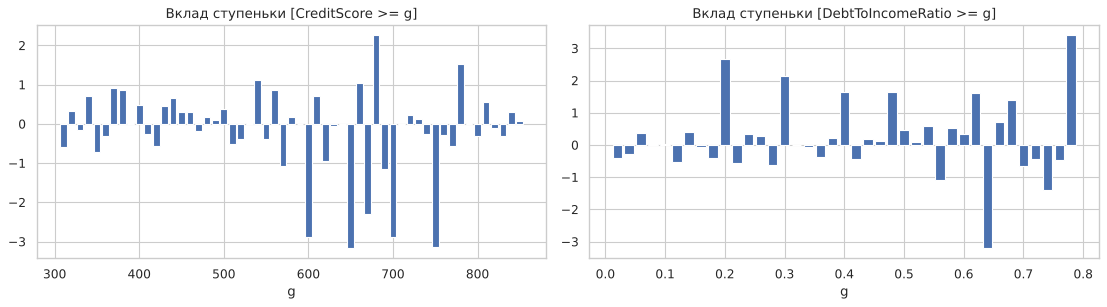

In [21]:
def step_profile(col, gr):
    """Линейная регрессия на ступеньках [col >= g] + остальные признаки (z-score). Возвращает коэффициенты ступенек."""
    S = np.column_stack([(train[col].values >= g) * 1.0 for g in gr])
    rest = MyStandardScaler().fit_transform(F.drop(columns=[c for c in F.columns if c.startswith(col) or c.endswith(col)]).values)
    m = MyLinearRegression('analytic', reg='l2', alpha=1e-4).fit(np.c_[S, rest], y)
    return m.coef_[:len(gr)]

grids = {'CreditScore': np.arange(310, 851, 10), 'DebtToIncomeRatio': np.round(np.arange(0.02, 0.8, 0.02), 2)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (col, gr) in zip(axes, grids.items()):
    coef = step_profile(col, gr)
    ax.bar(gr, coef, width=(gr[1] - gr[0]) * 0.8)
    ax.set_title(f'Вклад ступеньки [{col} >= g]'); ax.set_xlabel('g')
    print(col, '- самые большие скачки при g =', [round(float(v), 2) for v in gr[np.argsort(-np.abs(coef))[:6]]])
plt.tight_layout(); plt.show()

У `CreditScore` главные скачки сидят ровно на 600/650/700/750 (плюс 670/680). У `DebtToIncomeRatio` помимо шумных значений в редком «хвосте» (0.64, 0.78) выделяются 0.2, 0.3 и 0.4. Аналогичные профили для остальных переменных (годовой доход, `NetWorth`, `LengthOfCreditHistory`) дают пороги, которые собраны ниже. Набор порогов уточнён перебором кандидатов на круглых значениях: добавлялся только порог, улучшающий кросс-валидацию.

**Структура модели.** В данных есть два «режима» риска (два пика), и вклад одних и тех же признаков в них разный. Поэтому модель состоит из линейных регрессий трёх видов:
1. **Ветки.** Две линейные регрессии (низкий и высокий риск) на пороговых признаках и остальных признаках. Разметка объектов по веткам получается чередованием: обучили обе ветки → каждый объект отнесли к той, что точнее его предсказывает → переобучили (до сходимости).
2. **Вес верхней ветки.** Линейная регрессия по метке ветки на всех признаках; уточняется на «спорных» объектах (индекс между 0 и 1). Результат обрезается в [0, 1].
3. **Прогноз:** `ŷ = (1 − p)·ŷ_низкая + p·ŷ_высокая`.

Все составные части — линейная регрессия (с L2) из нашего класса `MyLinearRegression`.

In [22]:
thresholds = {   # пороги ступенчатых признаков [x >= порог]
    'CreditScore':           [600, 650, 700, 750],
    'DebtToIncomeRatio':     [0.2, 0.3, 0.4, 0.5],
    'AnnualIncome':          [30000, 50000, 80000, 120000],
    'NetWorth':              [50000, 100000, 200000, 250000, 500000, 1000000],
    'LengthOfCreditHistory': [3, 5, 7, 10],
}

def numeric_design(df):
    """Числовая матрица: все числовые столбцы + Age^2 + one-hot категорий (без дат, ID и BaseInterestRate)."""
    num = df.select_dtypes('number').drop(columns=['ID', 'RiskScore', 'BaseInterestRate'], errors='ignore').astype(float)
    num['Age2'] = num['Age'] ** 2
    cat = pd.get_dummies(df[cat_cols], drop_first=True, dtype=float)
    return pd.concat([num, cat], axis=1)

D_train = numeric_design(train)
D_test = numeric_design(test).reindex(columns=D_train.columns, fill_value=0.0)
print('Матрица:', D_train.shape)


class TwoBranchRegression:
    def __init__(self, columns, thresholds, lam=10.0, n_em=40, n_idx=6):
        self.columns, self.thr, self.lam, self.n_em, self.n_idx = list(columns), thresholds, lam, n_em, n_idx
        self.pos = {c: i for i, c in enumerate(self.columns)}

    def _ridge(self, X, t):                         # L2-регрессия нашим классом (alpha = lam / n -> штраф lam * ||w||^2 / 2n)
        return MyLinearRegression('analytic', reg='l2', alpha=self.lam / len(t)).fit(X, t)

    def _steps(self, X):                            # ступеньки + флаги (банкротство, дефолты, «не работает»)
        S = [(X[:, self.pos[c]][:, None] >= np.array(g)[None, :]) * 1.0 for c, g in self.thr.items()]
        emp = X[:, self.pos['EmploymentStatus_Self-Employed']] + X[:, self.pos['EmploymentStatus_Unemployed']]
        flags = np.column_stack([X[:, self.pos['BankruptcyHistory']], X[:, self.pos['PreviousLoanDefaults']], emp])
        return np.column_stack(S + [flags])

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        S = self._steps(X)
        # 1) чередование: обучить две ветки -> переназначить объекты -> повторять
        up = y > np.median(y)
        for _ in range(self.n_em):
            low_m, high_m = self._ridge(S[~up], y[~up]), self._ridge(S[up], y[up])
            new = np.abs(y - high_m.predict(S)) < np.abs(y - low_m.predict(S))
            if (new == up).all(): break
            up = new
        if high_m.predict(S).mean() < low_m.predict(S).mean(): up = ~up   # «верхняя» ветка = с большим риском
        self.up_ = up
        # 2) вес верхней ветки: линейная регрессия по метке, уточняем на спорных объектах
        self.sc_ = MyStandardScaler().fit(X); Z = self.sc_.transform(X)
        trans = np.ones(len(y), bool)
        for _ in range(self.n_idx):
            self.w_model_ = MyLinearRegression('analytic', reg='l2', alpha=1e-3 / trans.sum()).fit(Z[trans], up[trans] * 1.0)
            idx = self.w_model_.predict(Z); trans = (idx > 0) & (idx < 1)
            if trans.sum() < 200: break
        # 3) итоговые ветки: ступеньки + остальные признаки (z-score)
        self.extra_cols_ = [i for i, c in enumerate(self.columns) if c not in self.thr]
        self.es_ = MyStandardScaler().fit(X[:, self.extra_cols_])
        P = np.c_[S, self.es_.transform(X[:, self.extra_cols_])]
        self.low_, self.high_ = self._ridge(P[~up], y[~up]), self._ridge(P[up], y[up])
        return self

    def predict(self, X):
        X = np.asarray(X, float)
        p = np.clip(self.w_model_.predict(self.sc_.transform(X)), 0, 1)
        P = np.c_[self._steps(X), self.es_.transform(X[:, self.extra_cols_])]
        return (1 - p) * self.low_.predict(P) + p * self.high_.predict(P)

model = TwoBranchRegression(D_train.columns, thresholds)
model.fit(D_train.values, y)
print('Объектов в ветках (низкий риск / высокий риск):', (~model.up_).sum(), '/', model.up_.sum())
print('Число признаков в ветке:', model.low_.coef_.shape[0])

Матрица: (9332, 44)
Объектов в ветках (низкий риск / высокий риск): 4717 / 4615
Число признаков в ветке: 64


### Проверка модели: кросс-валидация и отложенная выборка

In [23]:
# Все оценки считаются только на объектах, не участвовавших в обучении (вся цепочка переобучается внутри каждого фолда)
cv5 = kfold_cv(TwoBranchRegression(D_train.columns, thresholds), D_train.values, y, k=5, seed=0)
cv10 = kfold_cv(TwoBranchRegression(D_train.columns, thresholds), D_train.values, y, k=10, seed=1)
print('5-fold  CV MSE по фолдам:', cv5.round(2), '-> среднее =', round(cv5.mean(), 3))
print('10-fold CV MSE по фолдам:', cv10.round(2), '-> среднее =', round(cv10.mean(), 3))

Xa, Xb, ya, yb = train_val_split(D_train.values, y, val_size=0.2, seed=0)
m = TwoBranchRegression(D_train.columns, thresholds).fit(Xa, ya); pb = m.predict(Xb)
print(f'\nHold-out (20%): MSE = {mse(yb, pb):.3f} | MAE = {mae(yb, pb):.3f} | R2 = {r2(yb, pb):.3f} | MAPE = {mape(yb, pb):.3f}')

# проверка отдельных линейных блоков против sklearn: ветка = ridge на тех же признаках
S_ = m._steps(Xa); up_ = m.up_
P_ = np.c_[S_, m.es_.transform(Xa[:, m.extra_cols_])]
print('Ветка (моя L2-регрессия) совпадает с sklearn Ridge:',
      np.allclose(m.low_.coef_, Ridge(alpha=m.lam).fit(P_[~up_], ya[~up_]).coef_, atol=1e-5))

5-fold  CV MSE по фолдам: [18.91 18.83 17.5  19.01 18.17] -> среднее = 18.485
10-fold CV MSE по фолдам: [20.99 17.13 17.51 17.8  17.3  20.2  18.27 17.17 18.06 19.97] -> среднее = 18.44

Hold-out (20%): MSE = 18.924 | MAE = 3.023 | R2 = 0.937 | MAPE = 0.069
Ветка (моя L2-регрессия) совпадает с sklearn Ridge: True


In [24]:
# Сводка по подходам (10-fold CV MSE, пороговое значение лабораторной = 25)
poly_cv = grid['CV MSE (10-fold)'].min()
pd.DataFrame({'MSE': [kfold_cv(MyLinearRegression('analytic'), Xz, y, k=10).mean(), poly_cv, cv10.mean()]},
             index=['линейная регрессия на исходных признаках', 'полиномиальные признаки (степень 4) + L2',
                    'пороговые признаки + две ветки (итог)'])

                                            MSE
линейная регрессия на исходных признаках 34.008
полиномиальные признаки (степень 4) + L2 23.820
пороговые признаки + две ветки (итог)    18.440

### Итоговое обучение на всём train и файл посылки

Формат совпадает с ex.csv: True | строк: 5000 / 5000 | ID совпадают: True
NaN в предсказаниях: 0
count   5000.000
mean      48.130
std       16.834
min       21.206
25%       32.674
50%       44.069
75%       64.878
max       94.158
Name: RiskScore, dtype: float64


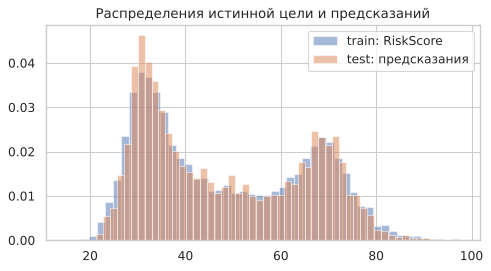

In [25]:
final = TwoBranchRegression(D_train.columns, thresholds).fit(D_train.values, y)
pred = final.predict(D_test.values)

submission = pd.DataFrame({'ID': test['ID'], 'RiskScore': pred})
submission.to_csv('submission.csv', index=False)

ex = pd.read_csv('ex.csv')
print('Формат совпадает с ex.csv:', list(submission.columns) == list(ex.columns), '| строк:', len(submission), '/', len(ex),
      '| ID совпадают:', (submission['ID'].values == ex['ID'].values).all())
print('NaN в предсказаниях:', submission['RiskScore'].isna().sum())
print(submission['RiskScore'].describe())

plt.figure(figsize=(7, 3.5))
plt.hist(y, bins=50, alpha=0.5, density=True, label='train: RiskScore')
plt.hist(pred, bins=50, alpha=0.5, density=True, label='test: предсказания')
plt.legend(); plt.title('Распределения истинной цели и предсказаний'); plt.show()

### Итоги
- **Порог лабораторной выполнен с запасом:** 10-fold CV MSE = **18.44** (5-fold: 18.49), hold-out (20%) MSE = 18.92, R² = 0.937, MAE = 3.02, MAPE = 6.9%. Все оценки считаются на объектах, не участвовавших в обучении (вся цепочка из трёх линейных регрессий переобучается внутри каждого фолда).
- **Сравнение подходов (10-fold CV MSE):** линейная регрессия на исходных признаках 34.0 → полиномиальные признаки 23.8 → пороговые признаки + две ветки **18.4**. Главный выигрыш дали пороговые признаки: `RiskScore` устроен как балльная система с порогами на круглых значениях, и гладкие полиномы её описывают плохо.
- Блоки модели — обычные линейные регрессии с L2 (проверено: ветка совпадает с `sklearn.Ridge`). Ничего, кроме линейной регрессии, не использовалось.
- Пороги выбраны на train: сначала по профилям скачков (график выше), затем перебором круглых кандидатов по кросс-валидации. Это даёт очень небольшую оптимистичность CV-оценки, поэтому реальный MSE на Kaggle может немного отличаться (по прошлому подходу test и CV отличались на ~0.3).
- Файл `submission.csv` (ID, RiskScore) сформирован в формате `ex.csv`.